![Banner](../images/09_09_banner_rs_image_classification.png)


# Instance Segmentation of Agricultural Fields with Mask R-CNN

Train and evaluate a geospatial, eight-band Mask R-CNN with GeoLattice using the WorldView-2 field polygons bundled with the image-classification data.


## Overview

Train and evaluate a geospatial, eight-band Mask R-CNN with GeoLattice using the WorldView-2 field polygons bundled with the image-classification data.

Semantic segmentation assigns a class to each pixel, but does not say which neighboring pixels belong to the same object. **Instance segmentation** predicts a separate mask for every object and assigns each mask a class and confidence. This notebook learns individual **Crop** and **Fallow** field instances from polygon labels, then converts predictions back to map-coordinate vector features.

The example uses `WorldView2_BD/Labeled_data/multi.tif` (eight multispectral bands) and `Labeled_data/aoi_trianing.shp` (567 field polygons). The training shapefile has no CRS metadata; its coordinates align with the raster and its associated metadata identifies UTM zone 46N, so the notebook assigns the raster CRS after checking that alignment. These are small, local teaching data, not a regionally representative accuracy benchmark.


## Core concepts

### Learning objectives

1. Distinguish semantic, object-detection and instance-segmentation outputs.
2. Convert georeferenced field polygons into per-instance chip masks and Mask R-CNN targets.
3. Build an eight-band detector with `geolattice.rsense.classify.image_classification`.
4. Train with a geographic holdout and evaluate instance-mask AP/IoU.
5. Convert predicted instance masks to georeferenced polygons with GeoLattice.

### Contents

1. Setup, data paths and compute device
2. WorldView-2 imagery and field-polygon labels
3. Instance rasterization, chip sampling and spatial split
4. Mask R-CNN architecture and objective
5. GeoLattice model, dataset and training loop
6. Spatial validation and mask-based metrics
7. Test-chip predictions and visual inspection
8. Georeferenced vectors and saved outputs
9. Interpretation, limitations and recommended recipe


### Task and evaluation design

A polygon is one instance; `Class_ID` supplies its category (1 = Fallow, 2 = Crop). Pixels outside labeled polygons are background. We split the image into contiguous north-to-south bands before making chips: the northern band trains, the middle band validates, and the southern band is held out for testing. Chips do not cross split boundaries. This is more conservative than randomly splitting neighboring chips, although this single small AOI still cannot establish geographic transfer performance.

The primary reported score is **mask AP at IoU 0.50**, calculated per class with one-to-one matching of predicted and reference masks. We also inspect per-instance mask IoU and vector geometry. Box AP alone is not used as a substitute for mask quality.


## Setup: libraries, device and data paths

The paths work from either the notebook directory or the repository root. Install the optional GeoLattice deep-learning and geospatial dependencies if needed (`geolattice[rsense-edge]` or `geolattice[rsense-dl,io]`). ImageNet/COCO initialization can download torchvision weights on first use; set `PRETRAINED = False` to avoid that download.

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import copy  # copy the best model weights
import time  # timing
import warnings  # warning control
from pathlib import Path  # file paths

import geopandas as gpd  # vector labels
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rasterio  # raster I/O
import rioxarray  # labelled raster I/O
import torch  # PyTorch
import xarray as xr  # labelled arrays
from rasterio.features import rasterize  # polygons -> raster
from rasterio.transform import Affine  # affine transforms
from torch.utils.data import DataLoader, Dataset  # PyTorch datasets and loaders

import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module

warnings.filterwarnings("ignore", category=UserWarning, module="rasterio")  # hide rasterio user warnings
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
if DEVICE == "cuda":  # on a GPU ...
    torch.backends.cudnn.benchmark = True  # ... let cuDNN pick fast kernels
print(f"GeoLattice {__import__('geolattice').__version__} | device={DEVICE}")  # GeoLattice version and device

DATA_CANDIDATES = [  # data folder seen from the notebook folder or from the repository root
    Path("../../../../Data/08_remote_sensing/08_09_image_classification/WorldView2_BD"),
    Path("Data/08_remote_sensing/08_09_image_classification/WorldView2_BD"),
]
# first candidate holding the image
DATA = next((p for p in DATA_CANDIDATES if (p / "Labeled_data/multi.tif").is_file()), None)
if DATA is None:  # not found ...
    # ... stop with a clear message
    raise FileNotFoundError("Could not locate ../../../../Data/08_remote_sensing/08_09_image_classification/WorldView2_BD/Labeled_data/multi.tif")
IMAGE_PATH = DATA / "Labeled_data/multi.tif"  # the eight-band WorldView-2 image
LABEL_PATH = DATA / "Labeled_data/aoi_trianing.shp"  # the field polygons
OUTPUT_DIR = DATA / "outputs/instance_segmentation"  # output folder
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # create it
print("Data:", DATA.resolve())  # data folder
print("Image:", IMAGE_PATH.name, "| labels:", LABEL_PATH.name)  # input files


GeoLattice 0.3.35 | device=cuda
Data: /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_09_image_classification/data/WorldView2_BD
Image: multi.tif | labels: aoi_trianing.shp


## WorldView-2 imagery and field-polygon labels

The labeled raster is a compact 760 × 702 pixel, eight-band subset. Band descriptions are not populated in the GeoTIFF, so channels are retained in source order and named `B1`-`B8`. The shapefile CRS is absent; the provided raster CRS is used as the label CRS only after confirming the polygon bounds overlap the raster bounds.


In [2]:
with rasterio.open(IMAGE_PATH) as src:  # open the image
    raw = src.read(masked=True).filled(np.nan).astype(np.float32)  # all bands, nodata as NaN
    raster_crs = src.crs  # its CRS
    raster_transform = src.transform  # its transform
    raster_bounds = src.bounds  # its bounds
    raster_nodata = src.nodata  # its nodata value
    height, width = src.height, src.width  # its size
    band_count = src.count  # number of bands
    band_names = [f"B{i}" for i in range(1, band_count + 1)]  # band names B1 to B8
    valid_pixels = np.all(np.isfinite(raw), axis=0)  # pixels with all bands present

if band_count != 8:  # eight bands expected ...
    raise ValueError(f"Expected the eight-band WorldView-2 stack, got {band_count} bands")  # ... or stop
if raster_crs is None:  # a CRS is needed ...
    raise ValueError("The source image needs a CRS for georeferenced instance outputs")  # ... or stop

labels = gpd.read_file(LABEL_PATH)  # read the polygons
if labels.crs is None:  # no CRS ...
    labels = labels.set_crs(raster_crs)  # ... assume the raster CRS
else:
    labels = labels.to_crs(raster_crs)  # otherwise reproject to it
labels = labels.loc[labels.geometry.notna() & ~labels.geometry.is_empty].copy()  # drop empty geometries
labels["Class_ID"] = labels["Class_ID"].astype(int)  # class id as integer
labels = labels[labels["Class_ID"].isin([1, 2])].reset_index(drop=True)  # keep Fallow (1) and Crop (2)

overlap_bounds = (  # labels and raster must overlap
    labels.total_bounds[0] < raster_bounds.right
    and labels.total_bounds[2] > raster_bounds.left
    and labels.total_bounds[1] < raster_bounds.top
    and labels.total_bounds[3] > raster_bounds.bottom
)
if not overlap_bounds:  # they do not ...
    raise ValueError("The polygon labels do not overlap the raster extent; check their CRS")  # ... stop

CLASS_NAMES = {1: "Fallow", 2: "Crop"}  # class names
CLASS_COLORS = {1: "#f2a900", 2: "#37a76f"}
# image size, bands, CRS and nodata
print(f"Image: {width} × {height}, {band_count} bands, CRS={raster_crs}, nodata={raster_nodata}")
print("Label CRS:", labels.crs, "| polygon count:", len(labels))  # label CRS and polygon count
print(labels["Class"].value_counts().rename("polygons"))  # polygons per class

image_da = xr.DataArray(  # the image as a georeferenced DataArray
    raw,
    dims=("band", "y", "x"),
    coords={"band": band_names},
    name="worldview2",
).rio.write_crs(raster_crs).rio.write_transform(raster_transform)

Image: 760 × 702, 8 bands, CRS=EPSG:32646, nodata=-3.3999999521443642e+38
Label CRS: PROJCS["WGS 84 / UTM zone 46N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",93],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32646"]] | polygon count: 567
Class
Crop      480
Fallow     87
Name: polygons, dtype: int64


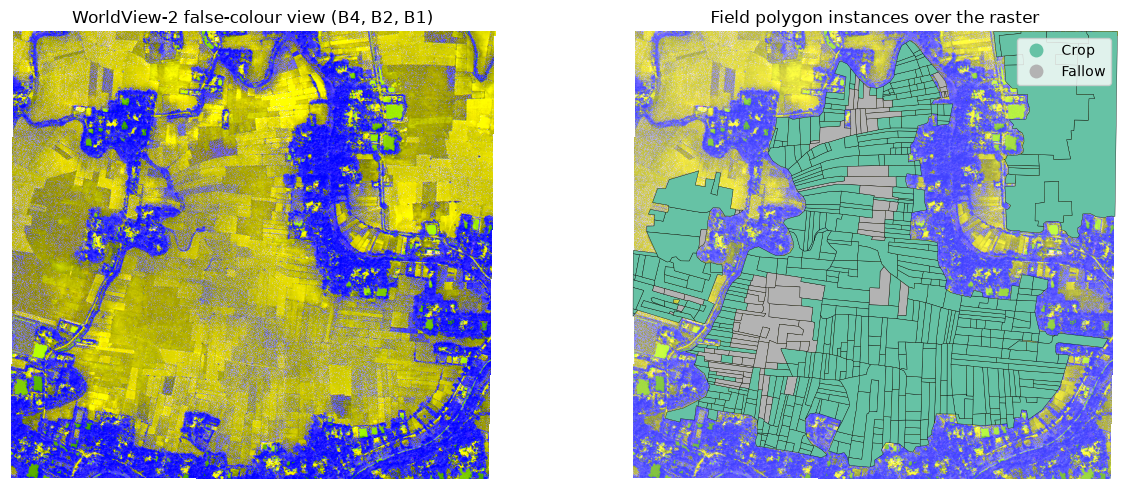

In [3]:
# A robust three-band display stretch; model input continues to use all eight bands.
display_bands = [4, 2, 1]
rgb = np.stack([  # 2 to 98 percentile stretch of each display band
    np.clip((raw[b - 1] - np.nanpercentile(raw[b - 1][valid_pixels], 2)) /
            (np.nanpercentile(raw[b - 1][valid_pixels], 98) - np.nanpercentile(raw[b - 1][valid_pixels], 2) + 1e-6), 0, 1)
    for b in display_bands
], axis=-1)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))  # two panels
ax[0].imshow(rgb)  # the image
ax[0].set_title("WorldView-2 false-colour view (B4, B2, B1)")  # title
ax[1].imshow(rgb, extent=(raster_bounds.left, raster_bounds.right,  # the image in map coordinates
                          raster_bounds.bottom, raster_bounds.top), alpha=0.75)
labels.plot(ax=ax[1], column="Class", categorical=True, legend=True,  # polygons coloured by class
            cmap="Set2", linewidth=0.25, edgecolor="black")
ax[1].set_title("Field polygon instances over the raster")  # title
for a in ax:  # each panel ...
    a.set_axis_off()  # ... without axes
plt.tight_layout()  # arrange

## Instance masks, patch sampling and spatial split

Rasterizing each polygon with its own integer identifier produces an **instance-ID image**, not merely a two-class semantic mask. Each ID retains its field class in `class_by_instance`; background is zero. Chips are generated within fixed row bands, so no chip can place neighboring train and test rows in the same sample. To avoid counting a field twice in chipwise test metrics, only complete, non-overlapping chips are evaluated; narrow remainder strips at image edges are omitted.


In [4]:
instance_shapes = []  # (geometry, id) pairs
class_by_instance = {}  # instance id -> class id
for instance_id, row in enumerate(labels.itertuples(), start=1):  # each polygon gets an id from 1
    instance_shapes.append((row.geometry, instance_id))  # its geometry and id
    class_by_instance[instance_id] = int(row.Class_ID)  # its class

instance_map = rasterize(  # burn the instance ids into a raster
    instance_shapes,
    out_shape=(height, width),
    transform=raster_transform,
    fill=0,
    dtype="int32",
    all_touched=False,
)
instance_map[~valid_pixels] = 0  # no instance where data are missing
class_map = np.zeros((height, width), dtype=np.uint8)  # class raster
for instance_id, class_id in class_by_instance.items():  # each instance ...
    class_map[instance_map == instance_id] = class_id  # ... paints its class
print("Rasterized instance IDs:", len(np.unique(instance_map)) - 1)  # number of instances
print("Labeled pixels:", int(np.count_nonzero(instance_map)))  # labelled pixels

PATCH = 160  # chip size in pixels
MIN_INSTANCE_PIXELS = 3  # smallest instance kept in a chip
# row bands for train, validation and test
ROW_BANDS = {"train": (0, 320), "validation": (320, 480), "test": (480, height)}

def full_window_starts(start, stop, patch):  # starts of full windows from start to stop
    return list(range(start, stop - patch + 1, patch))  # non-overlapping steps

col_starts = full_window_starts(0, width, PATCH)  # column starts
windows = {name: [] for name in ROW_BANDS}  # chip corners per split
for name, (row0, row1) in ROW_BANDS.items():  # each split
    for r0 in full_window_starts(row0, row1, PATCH):  # each row start
        for c0 in col_starts:  # each column start
            windows[name].append((r0, c0))  # one chip
print({name: len(coords) for name, coords in windows.items()}, "chips")  # chips per split
assert all(r + PATCH <= ROW_BANDS[name][1] and c + PATCH <= width  # every chip lies inside its own band
           for name, coords in windows.items() for r, c in coords)

Rasterized instance IDs: 567
Labeled pixels: 270473
{'train': 8, 'validation': 4, 'test': 4} chips


Instances per chip (train): [0, 14, 70, 13, 6, 47, 64, 7]
Train/validation/test chips: 8 4 4


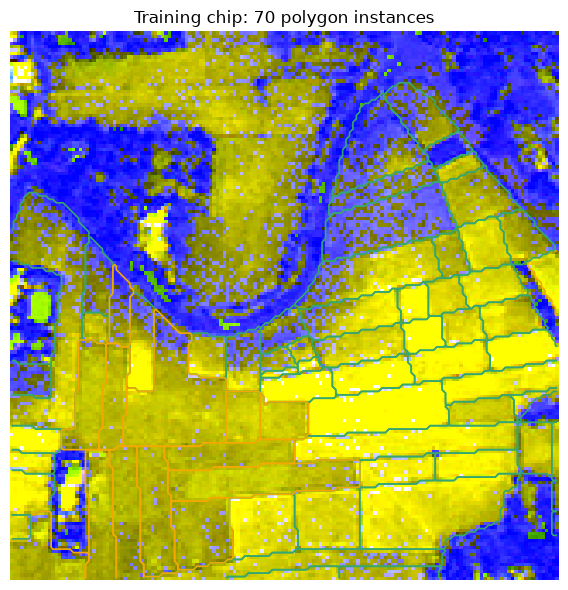

In [5]:
# Fit radiometric scaling on valid training-band pixels only.
train_valid = np.zeros_like(valid_pixels)
train_valid[:ROW_BANDS["train"][1]] = valid_pixels[:ROW_BANDS["train"][1]]  # valid pixels of the training band
lower = np.array([np.nanpercentile(np.where(train_valid, raw[b], np.nan), 2)  # 2nd percentile per band
                  for b in range(band_count)], dtype=np.float32)
upper = np.array([np.nanpercentile(np.where(train_valid, raw[b], np.nan), 98)  # 98th percentile per band
                  for b in range(band_count)], dtype=np.float32)
upper = np.maximum(upper, lower + 1e-6)  # avoid a zero range
scaled = np.clip((raw - lower[:, None, None]) /  # scale every band to 0 to 1
                 (upper - lower)[:, None, None], 0, 1)
scaled = np.nan_to_num(scaled, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)  # missing values -> 0

class InstanceChipDataset(Dataset):  # chips with instance masks, boxes and classes
    """Mask R-CNN samples: float image [C,H,W] and torchvision instance targets."""
    def __init__(self, coords):  # keep the chip corners
        self.coords = list(coords)  # the list of corners

    def __len__(self):  # number of chips
        return len(self.coords)  # the count

    def __getitem__(self, index):  # one chip and its target
        row0, col0 = self.coords[index]  # its corner
        sl = np.s_[row0:row0 + PATCH, col0:col0 + PATCH]  # its window
        chip = scaled[:, sl[0], sl[1]]  # the scaled bands
        ids = instance_map[sl]  # the instance ids
        masks, classes, boxes = [], [], []  # masks, classes and boxes
        for instance_id in np.unique(ids):  # each instance in the chip
            if instance_id == 0:  # skip the background
                continue
            mask = ids == instance_id  # its mask
            ys, xs = np.where(mask)  # its pixels
            if len(xs) < MIN_INSTANCE_PIXELS:  # skip tiny slivers
                continue
            masks.append(mask.astype(np.uint8))  # keep the mask
            classes.append(class_by_instance[int(instance_id)])  # its class
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])  # its bounding box
        if masks:  # any instances ...
            masks = torch.as_tensor(np.stack(masks), dtype=torch.uint8)  # ... masks as a tensor
            boxes = torch.as_tensor(boxes, dtype=torch.float32)  # boxes as a tensor
            classes = torch.as_tensor(classes, dtype=torch.int64)  # classes as a tensor
        else:
            masks = torch.zeros((0, PATCH, PATCH), dtype=torch.uint8)  # empty masks
            boxes = torch.zeros((0, 4), dtype=torch.float32)  # empty boxes
            classes = torch.zeros((0,), dtype=torch.int64)  # empty classes
        target = {  # the torchvision target dictionary
            "boxes": boxes,
            "labels": classes,
            "masks": masks,
            "image_id": torch.tensor([index], dtype=torch.int64),
            "area": masks.flatten(1).sum(1).to(torch.float32),
            "iscrowd": torch.zeros((len(classes),), dtype=torch.int64),
        }
        return torch.from_numpy(chip), target  # chip and target

train_ds = InstanceChipDataset(windows["train"])  # training chips
val_ds = InstanceChipDataset(windows["validation"])  # validation chips
test_ds = InstanceChipDataset(windows["test"])  # test chips
# instances in each training chip
print("Instances per chip (train):", [len(train_ds[i][1]["labels"]) for i in range(len(train_ds))])
print("Train/validation/test chips:", len(train_ds), len(val_ds), len(test_ds))  # chips per split

def detection_collate(batch):  # keep images and targets as tuples
    return tuple(zip(*batch))  # batch -> (images, targets)

BATCH_SIZE = 2 if DEVICE == "cuda" else 1  # batch size (smaller on a CPU)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  # shuffled training batches
                          collate_fn=detection_collate, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=1, shuffle=False,  # validation batches
                        collate_fn=detection_collate, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False,  # test batches
                         collate_fn=detection_collate, num_workers=0)

fig, ax = plt.subplots(figsize=(8, 6))  # one panel
# the training chip with most instances
sample_index = int(np.argmax([len(train_ds[i][1]["labels"]) for i in range(len(train_ds))]))
sample_image, sample_target = train_ds[sample_index]  # its image and target
ax.imshow(np.moveaxis(sample_image[[3, 1, 0]].numpy(), 0, -1))  # B4, B2, B1 as RGB
# each reference instance
for mask, label in zip(sample_target["masks"].numpy(), sample_target["labels"].numpy()):
    color = CLASS_COLORS[int(label)]  # its class colour
    ax.contour(mask, levels=[0.5], colors=[color], linewidths=1.2)  # its outline
ax.set_title(f"Training chip: {len(sample_target['labels'])} polygon instances")  # title
ax.axis("off")  # no axes
plt.tight_layout()  # arrange

## Mask R-CNN: architecture and objective

Mask R-CNN extends Faster R-CNN with a parallel mask head. A backbone and feature pyramid produce multi-scale features; the region proposal network (RPN) proposes candidate boxes; RoIAlign samples each proposal without the quantization error of RoI pooling; classification and box-regression heads refine each object; and a small fully convolutional mask head predicts a binary mask for each class and proposal.

For anchor $a$ and ground-truth box $b$, the RPN learns objectness and parameterized offsets. The final model minimizes

$$\mathcal L = \mathcal L_{rpn,obj} + \mathcal L_{rpn,box} + \mathcal L_{roi,cls} + \mathcal L_{roi,box} + \mathcal L_{mask}.$$

For a positive proposal assigned to class $k$, the mask head uses pixelwise binary cross-entropy only for channel $k$:

$$\mathcal L_{mask} = -\frac{1}{M^2}\sum_{u,v}\left[y_{uv}\log p_{uv,k} + (1-y_{uv})\log(1-p_{uv,k})\right].$$

This class-specific mask prediction keeps overlapping instances distinct. The GeoLattice builder replaces the COCO box and mask classifiers with heads for background, Fallow and Crop and adapts the ResNet input stem to all eight bands.


## Build the GeoLattice Mask R-CNN model

`build_object_detector("mask_rcnn", ...)` delegates construction to GeoLattice's torchvision detector builder. `num_classes` includes background, hence three outputs for two field classes plus background. ImageNet/COCO initialization is recommended for this small label set; the adapted first convolution accepts the eight-band input.


In [6]:
PRETRAINED = True  # start from COCO weights
model = ic.build_object_detector(  # Mask R-CNN for eight bands and two classes plus background
    "mask_rcnn",
    num_classes=len(CLASS_NAMES) + 1,
    in_channels=band_count,
    pretrained=PRETRAINED,
    min_size=PATCH,
    max_size=PATCH,
    image_mean=[0.5] * band_count,
    image_std=[0.25] * band_count,
).to(DEVICE)
model.roi_heads.detections_per_img = 100  # at most 100 detections per chip
model.rpn._pre_nms_top_n["training"] = 1000  # proposals before NMS (training)
model.rpn._post_nms_top_n["training"] = 300  # proposals after NMS (training)
model.rpn._pre_nms_top_n["testing"] = 500  # proposals before NMS (testing)
model.rpn._post_nms_top_n["testing"] = 150  # proposals after NMS (testing)
print(f"Built Mask R-CNN for {band_count} bands and {len(CLASS_NAMES)} foreground classes")  # report
# first convolution now takes eight bands
print("Backbone input channels:", model.backbone.body.conv1.in_channels)

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /home/zia207/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


  0%|          | 0.00/177M [00:00<?, ?B/s]

  0%|          | 128k/177M [00:00<02:49, 1.10MB/s]

  0%|          | 256k/177M [00:00<02:48, 1.10MB/s]

  0%|          | 512k/177M [00:00<02:10, 1.42MB/s]

  0%|          | 768k/177M [00:00<02:18, 1.34MB/s]

... (734 outputs left out)

100%|█████████▉| 177M/177M [02:08<00:00, 1.62MB/s]

100%|█████████▉| 177M/177M [02:08<00:00, 1.47MB/s]

100%|██████████| 177M/177M [02:08<00:00, 1.44MB/s]

Built Mask R-CNN for 8 bands and 2 foreground classes
Backbone input channels: 8


## Train on the spatial training band

Torchvision detectors consume a list of images and a matching list of targets. The compact loop below is necessary for Mask R-CNN's detection-specific loss dictionary; model construction, mask-to-vector conversion and export remain GeoLattice APIs. Validation mask AP selects the checkpoint. Reduce `EPOCHS` if training on CPU.


In [7]:
def mask_iou_matrix(pred_masks, true_masks):  # IoU of every predicted mask with every reference mask
    pred_masks = np.asarray(pred_masks, dtype=bool)  # as booleans
    true_masks = np.asarray(true_masks, dtype=bool)  # as booleans
    if len(pred_masks) == 0 or len(true_masks) == 0:  # none on one side ...
        return np.zeros((len(pred_masks), len(true_masks)), dtype=np.float32)  # ... an empty matrix
    p = pred_masks.reshape(len(pred_masks), -1)  # one row per predicted mask
    t = true_masks.reshape(len(true_masks), -1)  # one row per reference mask
    intersection = p.astype(np.uint32) @ t.astype(np.uint32).T  # pixel intersections
    union = p.sum(1)[:, None] + t.sum(1)[None, :] - intersection  # pixel unions
    return intersection / np.maximum(union, 1)  # IoU

def evaluate_mask_ap(model, loader, iou_threshold=0.5):  # mask AP at an IoU threshold for each class
    """All-point AP with greedy one-to-one matching on mask IoU, per foreground class."""
    model.eval()  # evaluation mode
    records = []  # per-chip predictions and references
    with torch.inference_mode():  # no gradients
        for images, targets in loader:  # each chip
            output = model([images[0].to(DEVICE)])[0]  # predict it
            pred_masks = (output["masks"][:, 0] >= 0.5).cpu().numpy()  # masks above 0.5
            records.append({  # keep predictions and references
                "pred_masks": pred_masks,
                "pred_labels": output["labels"].cpu().numpy(),
                "scores": output["scores"].cpu().numpy(),
                "true_masks": targets[0]["masks"].cpu().numpy().astype(bool),
                "true_labels": targets[0]["labels"].cpu().numpy(),
            })
    class_ap = {}  # AP per class
    for class_id, class_name in CLASS_NAMES.items():  # each class
        # reference instances of this class
        n_true = sum(int(np.sum(r["true_labels"] == class_id)) for r in records)
        if n_true == 0:  # none ...
            class_ap[class_name] = np.nan  # ... AP undefined
            continue
        detections = sorted(  # detections of this class, highest score first
            [(float(score), image_id, mask) for image_id, r in enumerate(records)
             for mask, label, score in zip(r["pred_masks"], r["pred_labels"], r["scores"])
             if label == class_id],
            key=lambda item: item[0], reverse=True,
        )
        matched = {i: set() for i in range(len(records))}  # reference instances already matched
        tp, fp = [], []  # true and false positives
        for score, image_id, pred_mask in detections:  # each detection
            record = records[image_id]  # its chip
            keep = record["true_labels"] == class_id  # references of this class
            gt_masks = record["true_masks"][keep]  # their masks
            ious = mask_iou_matrix(pred_mask[None], gt_masks)[0]  # IoU with each reference
            best = int(np.argmax(ious)) if len(ious) else -1  # best reference
            # good enough and still free ...
            if best >= 0 and ious[best] >= iou_threshold and best not in matched[image_id]:
                matched[image_id].add(best)  # ... mark it matched
                tp.append(1)  # true positive
                fp.append(0)  # not a false positive
            else:
                tp.append(0)  # not a true positive
                fp.append(1)  # false positive
        if not tp:  # no detections ...
            class_ap[class_name] = 0.0  # ... AP is zero
            continue
        recall = np.cumsum(tp) / n_true  # recall curve
        precision = np.cumsum(tp) / np.maximum(np.cumsum(tp) + np.cumsum(fp), 1)  # precision curve
        mrec = np.r_[0.0, recall, 1.0]  # recall padded at both ends
        mpre = np.r_[0.0, precision, 0.0]  # precision padded at both ends
        for j in range(len(mpre) - 2, -1, -1):  # from right to left ...
            mpre[j] = max(mpre[j], mpre[j + 1])  # ... make precision non-increasing
        changes = np.where(mrec[1:] != mrec[:-1])[0]  # points where recall changes
        # area under the precision-recall curve
        class_ap[class_name] = float(np.sum((mrec[changes + 1] - mrec[changes]) * mpre[changes + 1]))
    finite = [v for v in class_ap.values() if np.isfinite(v)]  # defined APs
    return float(np.mean(finite)) if finite else np.nan, class_ap  # mean AP and per-class APs

EPOCHS = 5 if DEVICE == "cuda" else 2  # epochs (fewer on a CPU)
# AdamW on the trainable weights
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                              lr=2e-4, weight_decay=1e-4)
history = []  # per-epoch log
best_state = None  # best weights so far
best_val_ap = -np.inf  # best validation AP so far
for epoch in range(EPOCHS):  # each epoch
    model.train()  # training mode
    loss_sums = {}  # summed losses
    n_batches = 0  # batch count
    started = time.time()  # start the timer
    for images, targets in train_loader:  # each batch
        images = [image.to(DEVICE) for image in images]  # images to the device
        targets = [{k: v.to(DEVICE) for k, v in target.items()} for target in targets]  # targets to the device
        optimizer.zero_grad(set_to_none=True)  # clear gradients
        loss_dict = model(images, targets)  # the five Mask R-CNN losses
        total_loss = sum(loss_dict.values())  # their sum
        if not torch.isfinite(total_loss):  # stop if the loss is not finite ...
            # ... with a clear message
            raise FloatingPointError(f"Non-finite training loss at epoch {epoch + 1}")
        total_loss.backward()  # gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)  # clip large gradients
        optimizer.step()  # update the weights
        for key, value in loss_dict.items():  # each loss term ...
            loss_sums[key] = loss_sums.get(key, 0.0) + float(value.detach())  # ... added up
        n_batches += 1  # count the batch
    mean_loss = sum(loss_sums.values()) / max(n_batches, 1)  # mean loss per batch
    val_ap, val_by_class = evaluate_mask_ap(model, val_loader)  # validation AP
    history.append({"epoch": epoch + 1, "train_loss": mean_loss,  # log the epoch
                    "val_mask_ap50": val_ap, **{f"val_ap_{k}": v for k, v in val_by_class.items()}})
    if np.isfinite(val_ap) and val_ap > best_val_ap:  # better validation AP ...
        best_val_ap = val_ap  # ... remember it
        best_state = copy.deepcopy(model.state_dict())  # ... and the weights
    print(f"epoch {epoch + 1:02d}/{EPOCHS} | loss={mean_loss:.3f} | "  # progress line
          f"val mask AP50={val_ap:.3f} | {time.time() - started:.1f}s")

if best_state is not None:  # best weights found ...
    model.load_state_dict(best_state)  # ... restore them
else:
    # otherwise keep the last epoch
    warnings.warn("Validation AP was unavailable; retaining the final epoch weights")
history = pd.DataFrame(history)  # log as a table
history  # show it

epoch 01/5 | loss=5.096 | val mask AP50=0.000 | 6.5s


epoch 02/5 | loss=2.807 | val mask AP50=0.002 | 2.7s


epoch 03/5 | loss=2.065 | val mask AP50=0.006 | 2.6s


epoch 04/5 | loss=1.966 | val mask AP50=0.004 | 2.7s


epoch 05/5 | loss=1.880 | val mask AP50=0.008 | 2.9s


,epoch,train_loss,val_mask_ap50,val_ap_Fallow,val_ap_Crop
0,1,5.096091,0.000000,0.000000,0.000000
1,2,2.806761,0.001551,0.000000,0.003102
2,3,2.065221,0.006340,0.002778,0.009902
3,4,1.966044,0.003526,0.000000,0.007052
4,5,1.880046,0.008198,0.002778,0.013618


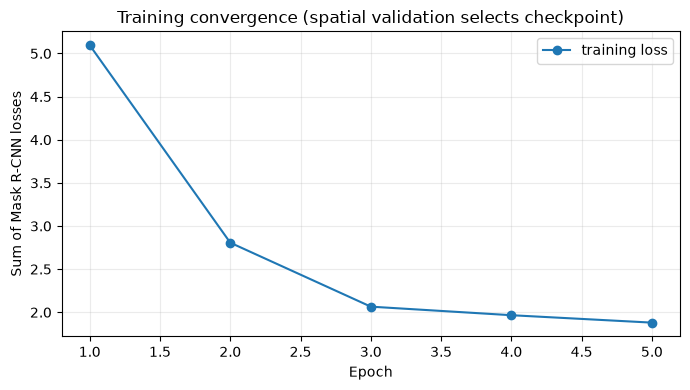

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))  # one panel
ax.plot(history["epoch"], history["train_loss"], marker="o", label="training loss")  # training loss per epoch
ax.set_xlabel("Epoch")  # x label
ax.set_ylabel("Sum of Mask R-CNN losses")  # y label
ax.set_title("Training convergence (spatial validation selects checkpoint)")  # title
ax.grid(alpha=0.25)  # light grid
ax.legend()  # legend
plt.tight_layout()  # arrange

## Held-out spatial evaluation: mask AP and instance IoU

The test band is not used for optimization or checkpoint choice. The AP implementation uses confidence-ranked, one-to-one matching within each chip. A match is a true positive only when the predicted and reference **binary masks** have IoU ≥ 0.50; duplicate matches and unmatched predictions count as false positives. AP is averaged across classes with test references.


In [9]:
# AP at IoU 0.5 on the test chips
test_mask_ap50, test_ap_by_class = evaluate_mask_ap(model, test_loader, iou_threshold=0.50)
print(f"Test mask mAP@0.50: {test_mask_ap50:.3f}")  # headline score
display(pd.DataFrame({"class": list(test_ap_by_class),  # AP per class
                      "mask_AP50": list(test_ap_by_class.values())}))

# IoU of each matched test instance
def test_instance_ious(model, dataset, score_threshold=0.5, iou_threshold=0.5):
    rows = []  # result rows
    model.eval()  # evaluation mode
    with torch.inference_mode():  # no gradients
        for index in range(len(dataset)):  # each test chip
            image, target = dataset[index]  # its image and target
            output = model([image.to(DEVICE)])[0]  # predict it
            pred_masks = (output["masks"][:, 0] >= 0.5).cpu().numpy()  # predicted masks
            pred_labels = output["labels"].cpu().numpy()  # predicted classes
            scores = output["scores"].cpu().numpy()  # confidence scores
            true_masks = target["masks"].numpy().astype(bool)  # reference masks
            true_labels = target["labels"].numpy()  # reference classes
            for class_id, class_name in CLASS_NAMES.items():  # each class
                # confident predictions of this class
                pm = [m for m, lb, sc in zip(pred_masks, pred_labels, scores)
                      if lb == class_id and sc >= score_threshold]
                tm = true_masks[true_labels == class_id]  # references of this class
                ious = mask_iou_matrix(np.asarray(pm), tm)  # IoU matrix
                pairs = []  # all prediction-reference pairs
                for p in range(len(pm)):  # each prediction ...
                    for t in range(len(tm)):  # ... and each reference ...
                        pairs.append((ious[p, t], p, t))  # ... with their IoU
                used_p, used_t = set(), set()  # used predictions and references
                for iou, p, t in sorted(pairs, reverse=True):  # best pairs first
                    if iou < iou_threshold:  # below the threshold ...
                        break
                    if p not in used_p and t not in used_t:  # both still free ...
                        used_p.add(p)  # ... use the prediction
                        used_t.add(t)  # ... and the reference
                        # record the match
                        rows.append({"chip": index, "class": class_name, "mask_IoU": float(iou)})
    return pd.DataFrame(rows)  # as a table

matched_ious = test_instance_ious(model, test_ds)  # matched test instances
if len(matched_ious):  # any matches ...
    # ... count, mean and median IoU per class
    display(matched_ious.groupby("class")["mask_IoU"].agg(["count", "mean", "median"]))
else:
    # none matched
    print("No test instances passed the score and IoU thresholds; inspect predictions and labels.")

Test mask mAP@0.50: 0.006


,class,mask_AP50
0,Fallow,0.000000
1,Crop,0.012462


No test instances passed the score and IoU thresholds; inspect predictions and labels.


## Test-chip predictions: inspect masks, not only scores

The predicted masks are overlaid on a three-band display composite; reference polygon masks are shown separately for comparison. Low scores and partial fields near chip edges are expected in this compact demonstration. A chipwise prediction avoids implying that a seamless scene-wide mosaic has been evaluated.


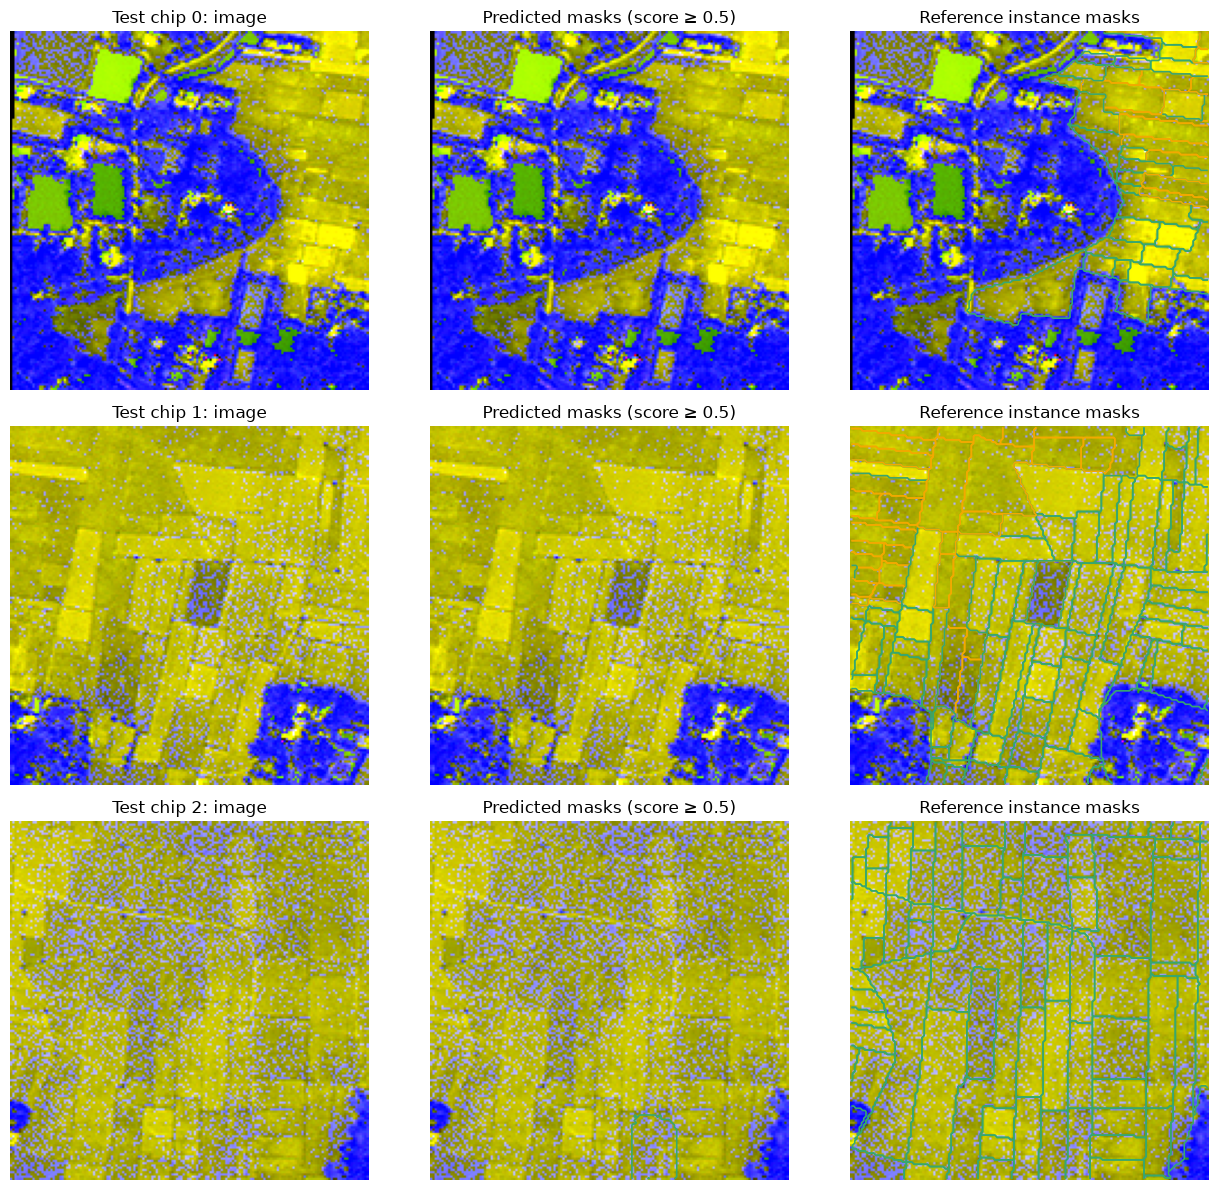

In [10]:
# draw instance outlines in their class colours
def draw_instance_masks(ax, masks, class_ids, scores=None, threshold=0.5):
    for i, (mask, class_id) in enumerate(zip(masks, class_ids)):  # each mask
        if scores is not None and scores[i] < threshold:  # below the score threshold ...
            continue
        color = CLASS_COLORS.get(int(class_id), "white")  # class colour
        ax.contour(mask.astype(float), levels=[0.5], colors=[color], linewidths=1.2)  # outline

model.eval()  # evaluation mode
preview_ids = list(range(min(3, len(test_ds))))  # first three test chips
# three panels per chip
fig, axes = plt.subplots(len(preview_ids), 3, figsize=(13, 4 * len(preview_ids)), squeeze=False)
with torch.inference_mode():  # no gradients
    for row_i, index in enumerate(preview_ids):  # each chip
        image, target = test_ds[index]  # its image and target
        output = model([image.to(DEVICE)])[0]  # predict it
        rgb_chip = np.moveaxis(image[[3, 1, 0]].numpy(), 0, -1)  # B4, B2, B1 as RGB
        pred_masks = (output["masks"][:, 0] >= 0.5).cpu().numpy()  # predicted masks
        pred_labels = output["labels"].cpu().numpy()  # predicted classes
        pred_scores = output["scores"].cpu().numpy()  # confidence scores
        axes[row_i, 0].imshow(rgb_chip)  # image
        axes[row_i, 0].set_title(f"Test chip {index}: image")  # title
        axes[row_i, 1].imshow(rgb_chip)  # image
        # predicted outlines
        draw_instance_masks(axes[row_i, 1], pred_masks, pred_labels, pred_scores, threshold=0.5)
        axes[row_i, 1].set_title("Predicted masks (score ≥ 0.5)")  # title
        axes[row_i, 2].imshow(rgb_chip)  # image
        # reference outlines
        draw_instance_masks(axes[row_i, 2], target["masks"].numpy(), target["labels"].numpy())
        axes[row_i, 2].set_title("Reference instance masks")  # title
        for a in axes[row_i]:  # each panel ...
            a.axis("off")  # ... without axes
plt.tight_layout()  # arrange

## Georeferenced instance polygons with GeoLattice

`instances_from_detector` converts each Mask R-CNN output mask to a polygon using the chip's own CRS and affine transform. `export_vectors` writes a GeoPackage. The exported features retain predicted class, confidence and area; they are model proposals and should not be treated as authoritative field boundaries without visual review.


In [11]:
vector_parts = []  # polygons per chip
prediction_rows = []  # raw outputs
model.eval()  # evaluation mode
with torch.inference_mode():  # no gradients
    for chip_index, (row0, col0) in enumerate(windows["test"]):  # each test chip
        chip = torch.from_numpy(scaled[:, row0:row0 + PATCH, col0:col0 + PATCH])  # its scaled bands
        output = model([chip.to(DEVICE)])[0]  # predict it
        prediction_rows.append(output)  # keep the output
        # the matching image window
        chip_da = image_da.isel(y=slice(row0, row0 + PATCH), x=slice(col0, col0 + PATCH))
        chip_da = chip_da.rio.write_transform(  # shift the transform to the chip corner
            raster_transform * Affine.translation(col0, row0)
        )
        vectors = ic.instances_from_detector(  # masks -> georeferenced polygons
            output,
            chip_da,
            score_threshold=0.5,
            mask_threshold=0.5,
            class_names=CLASS_NAMES,
            simplify=0.5,
        )
        if len(vectors):  # any polygons ...
            vectors["chip_id"] = chip_index  # ... tag them with the chip
            vector_parts.append(vectors)  # ... and keep them

if vector_parts:  # polygons found ...
    predicted_fields = gpd.GeoDataFrame(pd.concat(vector_parts, ignore_index=True),  # ... one GeoDataFrame
                                        geometry="geometry", crs=raster_crs)
else:
    predicted_fields = gpd.GeoDataFrame(  # otherwise an empty one
        {"label": [], "class_name": [], "confidence": [], "area": [], "chip_id": []},
        geometry=[], crs=raster_crs,
    )
vector_path = OUTPUT_DIR / "mask_rcnn_test_instances.gpkg"  # output GeoPackage
if len(predicted_fields):  # anything to write ...
    ic.export_vectors(predicted_fields, vector_path, layer="predicted_instances")  # ... export it
    display(predicted_fields.drop(columns="geometry").head())  # first rows
    print(f"Saved {len(predicted_fields)} predicted instances to {vector_path}")  # report
else:
    # nothing written
    print("No instances exceeded the vector-export score threshold; no vector file was written.")

,label,class_name,confidence,area,chip_id
0,2,Crop,0.636721,1405.44,2


Saved 1 predicted instances to data/WorldView2_BD/outputs/instance_segmentation/mask_rcnn_test_instances.gpkg


## Summary of the experiment

The table reports validation-selected training history, held-out test mask AP, matched-mask IoU, and the number of georeferenced test predictions. Scores depend strongly on initialization, threshold, sparse annotations, and the spatial holdout; use them to inspect the workflow rather than to claim production accuracy.


In [12]:
summary = pd.DataFrame([  # summary table
    {"quantity": "training chips", "value": len(train_ds)},
    {"quantity": "validation chips", "value": len(val_ds)},
    {"quantity": "test chips", "value": len(test_ds)},
    {"quantity": "reference field polygons", "value": len(labels)},
    {"quantity": "test mask mAP@0.50", "value": test_mask_ap50},
    {"quantity": "matched test instances (IoU ≥ 0.50)", "value": len(matched_ious)},
    {"quantity": "exported test predictions", "value": len(predicted_fields)},
])
display(summary)  # show it
print("Per-class test AP50:", test_ap_by_class)  # AP per class

,quantity,value
0,training chips,8.000000
1,validation chips,4.000000
2,test chips,4.000000
3,reference field polygons,567.000000
4,test mask mAP@0.50,0.006231
5,matched test instances (IoU ≥ 0.50),0.000000
6,exported test predictions,1.000000


Per-class test AP50: {'Fallow': 0.0, 'Crop': 0.012462432267653286}


## Interpretation, caveats and recommended recipe

- **Instance segmentation is not box detection.** Every prediction has a pixel mask; bounding boxes are auxiliary proposal targets. Tree-detection files in this data folder are box annotations and are intentionally not repurposed as instance masks.
- **The source labels are field polygons.** Rasterization introduces grid effects, narrow polygons can disappear at 1.6 m pixels, and neighboring/overlapping annotations may compete for pixels. Inspect the rasterized mask overlay before interpreting scores.
- **The split is spatial but small.** Contiguous row bands reduce direct chip leakage; they do not represent independent farms, seasons or sensors. The test set is one geographic strip.
- **Eight-band scaling matters.** Percentile bounds are fitted from training rows and reused unchanged. For another WorldView-2 scene, repeat radiometric preprocessing consistently and verify band order and calibration.
- **Model scores are not calibrated confidence.** Mask AP at a fixed IoU threshold combines localization and classification; report per-class results and inspect errors, especially touching fields and chip-edge truncation.
- **Recommended extension:** collect spatially independent polygon labels, reserve a separate farm/AOI for final evaluation, compare pretrained and scratch starts, tune score/mask thresholds on validation only, and quantify uncertainty across multiple spatial folds.

The predicted GeoPackage is a reviewable vector product. Keep the raster, transform, CRS, class mapping and preprocessing metadata with any downstream field-area analysis.
